# CPPN genomes: a small neural network that grows

A CPPN genome (NEAT style) is a small neural network stored as nodes and weighted connections. It starts as inputs wired straight to outputs and grows by mutation: a new connection, or a new node on an old connection. In ARIEL such a network is queried to decide a robot's body. In this notebook you create a genome, run it, grow it with mutations, cross two parents over, and save and load it. Each genome is drawn: nodes in columns, line width for the weight size, red lines for negative weights. No graphics backend is needed.

In [1]:
# Standard library
import json
import random

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import Genome, IdManager

In [4]:
# Seed and sizes
SEED = 42
random.seed(SEED)  # Genome draws its weights from the random module
RNG = np.random.default_rng(SEED)
INPUTS = 3
OUTPUTS = 2
FIRST_INNOV = 0
BATCH = 200

## Drawing a genome

One helper draws a genome as a left-to-right graph: inputs on the left, outputs on the right, hidden nodes between them. Disabled connections are dashed.

In [5]:
def draw(genome: Genome, axis: plt.Axes, title: str) -> None:
    graph = nx.DiGraph()
    for node_id, node in genome.nodes.items():
        graph.add_node(node_id, kind=node.typ)
    for connection in genome.connections.values():
        graph.add_edge(connection.in_id, connection.out_id)
    layer = {"input": 0, "hidden": 1, "output": 2}
    for _, data in graph.nodes(data=True):
        data["layer"] = layer[data["kind"]]
    positions = nx.multipartite_layout(graph, subset_key="layer")
    colours = {"input": "tab:green", "hidden": "tab:blue", "output": "tab:red"}
    nx.draw_networkx_nodes(
        graph,
        positions,
        ax=axis,
        node_color=[colours[d["kind"]] for _, d in graph.nodes(data=True)],
    )
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color="white")
    for connection in genome.connections.values():
        nx.draw_networkx_edges(
            graph,
            positions,
            ax=axis,
            edgelist=[(connection.in_id, connection.out_id)],
            width=0.5 + 3 * abs(connection.weight),
            edge_color="tab:red" if connection.weight < 0 else "black",
            style="solid" if connection.enabled else "dashed",
        )
    sizes = f"{len(genome.nodes)} nodes, {len(genome.connections)} connections"
    axis.set_title(f"{title}: {sizes}")

## A random genome and what it computes

`Genome.random` wires every input to every output with random weights. `activate` runs the network on a list of input values and returns one value per output; the default activation is a sigmoid, so outputs lie between 0 and 1.

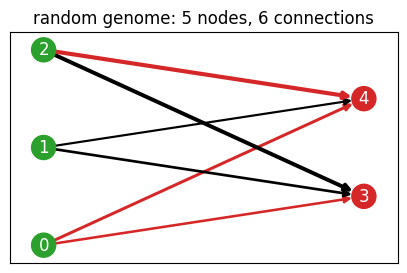

In [6]:
genome = Genome.random(INPUTS, OUTPUTS, INPUTS + OUTPUTS, FIRST_INNOV)
fig, axis = plt.subplots(figsize=(5, 3))
draw(genome, axis, "random genome")
plt.show()

In [7]:
inputs = [0.1, 0.5, -0.3]
outputs = genome.activate(inputs)
console.print(f"inputs {inputs} -> outputs {outputs}")
assert len(genome.connections) == INPUTS * OUTPUTS
assert len(outputs) == OUTPUTS
assert all(0 <= value <= 1 for value in outputs)
assert outputs == genome.activate(inputs)  # same input, same output

inputs [0.1, 0.5, -0.3] -> outputs [0.5584867675275944, 0.3587484990115916]

## Growing by mutation

`mutate` adds a connection and/or a node, with the given probabilities. New ids come from an `IdManager`, which hands out node and innovation numbers that are unique across the whole run. Rates of 1.0 force both mutations every time, so growth is easy to see.

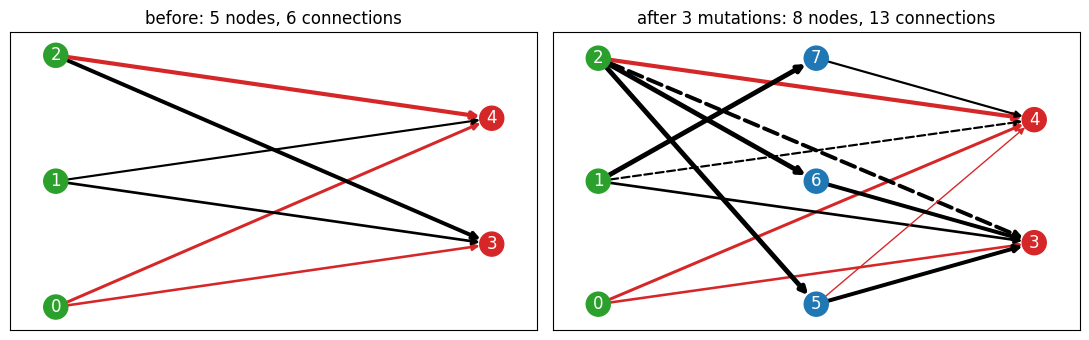

In [8]:
ids = IdManager(
    node_start=INPUTS + OUTPUTS - 1,
    innov_start=FIRST_INNOV + INPUTS * OUTPUTS - 1,
)
grown = genome.copy()
for _ in range(3):
    grown.mutate(
        node_add_rate=1.0,
        conn_add_rate=1.0,
        next_innov_id_getter=ids.get_next_innov_id,
        next_node_id_getter=ids.get_next_node_id,
    )
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
draw(genome, axes[0], "before")
draw(grown, axes[1], "after 3 mutations")
plt.tight_layout()
plt.show()

In [9]:
assert len(grown.nodes) > len(genome.nodes)
assert len(grown.connections) > len(genome.connections)
assert (
    len(genome.connections) == INPUTS * OUTPUTS
)  # the copy was grown, not the original
assert len(grown.activate(inputs)) == OUTPUTS

## Crossover

`crossover` builds a child from two parents. Genes are matched by innovation number: matching genes come from either parent at random, and genes only one parent has come from the **fitter** parent (the other parent's own genes are kept only when the fitness is equal). `is_maximisation` says whether a higher or a lower fitness is fitter. The test below runs many random pairs in both modes and checks that the child always has every gene of the fitter parent.

In [10]:
def random_parent(fitness: float) -> Genome:
    parent = Genome.random(INPUTS, OUTPUTS, INPUTS + OUTPUTS, FIRST_INNOV)
    for _ in range(RNG.integers(0, 4)):
        parent.mutate(1.0, 1.0, ids.get_next_innov_id, ids.get_next_node_id)
    parent.fitness = fitness
    return parent


for is_maximisation in (True, False):
    for _ in range(BATCH):
        a = random_parent(float(RNG.integers(0, 6)))
        b = random_parent(float(RNG.integers(0, 6)))
        if a.fitness == b.fitness:
            continue
        child = a.crossover(b, is_maximisation=is_maximisation)
        a_is_fitter = (a.fitness > b.fitness) == is_maximisation
        fitter = a if a_is_fitter else b
        assert set(fitter.connections) <= set(child.connections)
console.print(
    f"{2 * BATCH} crossovers: every child kept all genes of the fitter parent"
)

400 crossovers: every child kept all genes of the fitter parent

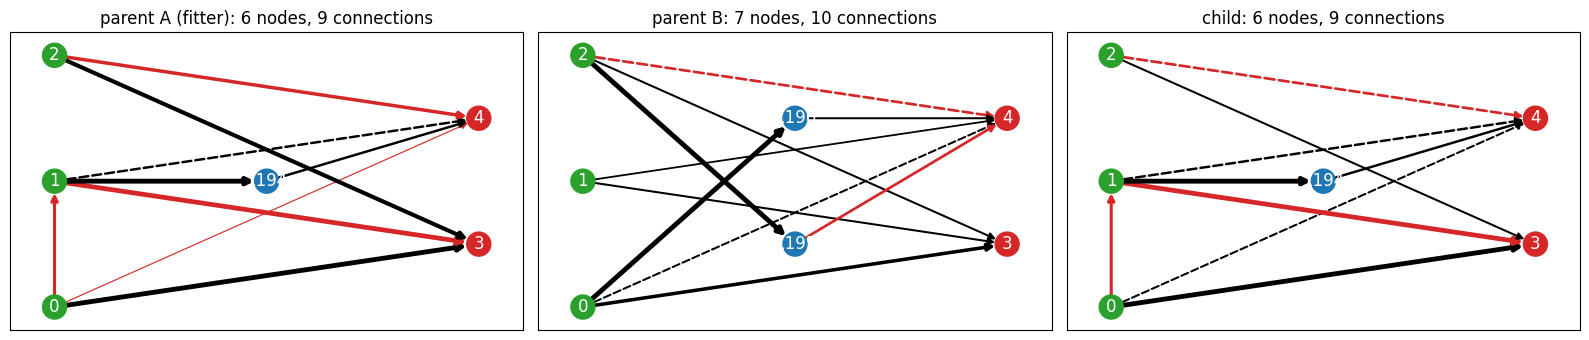

In [11]:
parent_a = random_parent(100.0)
parent_b = random_parent(50.0)
child = parent_a.crossover(parent_b)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
draw(parent_a, axes[0], "parent A (fitter)")
draw(parent_b, axes[1], "parent B")
draw(child, axes[2], "child")
plt.tight_layout()
plt.show()
assert set(parent_a.connections) <= set(child.connections)
assert len(child.activate(inputs)) == OUTPUTS

## Save and load

`to_dict` gives a JSON-friendly dict and `from_dict` rebuilds the genome from it. A rebuilt genome computes the same outputs.

In [12]:
text = json.dumps(grown.to_dict())
restored = Genome.from_dict(json.loads(text))
console.print(f"{len(text)} characters of JSON")
assert set(restored.connections) == set(grown.connections)
assert restored.activate(inputs) == grown.activate(inputs)

1779 characters of JSON